In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/raw/LongitudinalEngagement.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1136, 15)


In [3]:
print("Column names:")
print(df.columns.tolist())

Column names:
['UserID', 'CourseID', 'Sequence', 'Freq_Course_View', 'Freq_Forum_Consume', 'Freq_Forum_Contribute', 'Freq_Lecture_View', 'Regularity_Course_View', 'Regularity_Lecture_View', 'Regularity_Forum_Consume', 'Regularity_Forum_Contribute', 'Session_Count', 'Total_Duration', 'Active_Days', 'Final_Grade']


In [4]:
print("Number of unique users:", df["UserID"].nunique())

Number of unique users: 142


In [5]:
records_per_user = df.groupby("UserID").size()

print(records_per_user.describe())

count    142.0
mean       8.0
std        0.0
min        8.0
25%        8.0
50%        8.0
75%        8.0
max        8.0
dtype: float64


In [6]:
print("Unique sequence values:")
print(sorted(df["Sequence"].unique()))

Unique sequence values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [7]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
UserID                         0
CourseID                       0
Sequence                       0
Freq_Course_View               0
Freq_Forum_Consume             0
Freq_Forum_Contribute          0
Freq_Lecture_View              0
Regularity_Course_View         0
Regularity_Lecture_View        0
Regularity_Forum_Consume       0
Regularity_Forum_Contribute    0
Session_Count                  0
Total_Duration                 0
Active_Days                    0
Final_Grade                    0
dtype: int64


In [8]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [9]:
print(df.dtypes)

UserID                             str
CourseID                           str
Sequence                         int64
Freq_Course_View                 int64
Freq_Forum_Consume               int64
Freq_Forum_Contribute            int64
Freq_Lecture_View                int64
Regularity_Course_View         float64
Regularity_Lecture_View        float64
Regularity_Forum_Consume       float64
Regularity_Forum_Contribute    float64
Session_Count                    int64
Total_Duration                   int64
Active_Days                      int64
Final_Grade                    float64
dtype: object


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Sequence,1136.0,4.500000,2.292297,1.00,2.7500,4.500,6.25,8.00
Freq_Course_View,1136.0,220.324824,64.952664,32.00,178.0000,220.500,264.00,440.00
Freq_Forum_Consume,1136.0,584.036092,177.423552,84.00,465.7500,589.500,701.25,1091.00
Freq_Forum_Contribute,1136.0,177.749120,53.283776,17.00,143.0000,178.500,212.00,358.00
Freq_Lecture_View,1136.0,201.432218,60.663881,19.00,160.0000,202.000,244.00,402.00
Regularity_Course_View,1136.0,0.498178,0.147380,0.08,0.4000,0.500,0.60,0.92
Regularity_Lecture_View,1136.0,0.482165,0.151218,0.02,0.3800,0.490,0.59,0.90
Regularity_Forum_Consume,1136.0,0.497984,0.144654,0.05,0.4000,0.510,0.59,0.95
Regularity_Forum_Contribute,1136.0,0.495158,0.152722,0.03,0.3900,0.490,0.60,0.93
Session_Count,1136.0,184.809859,55.542617,27.00,146.7500,187.000,223.00,326.00


In [11]:
sequence_summary = df.groupby("Sequence")[
    [
        "Freq_Course_View",
        "Freq_Forum_Consume",
        "Freq_Forum_Contribute",
        "Freq_Lecture_View",
        "Session_Count",
        "Active_Days",
        "Final_Grade"
    ]
].mean()

sequence_summary

,Freq_Course_View,Freq_Forum_Consume,Freq_Forum_Contribute,Freq_Lecture_View,Session_Count,Active_Days,Final_Grade
Sequence,,,,,,,
1,213.795775,572.464789,174.345070,196.204225,180.204225,15.690141,67.784085
2,219.387324,588.049296,178.197183,201.436620,185.760563,15.992958,68.542746
3,218.380282,571.492958,174.535211,201.239437,181.859155,15.753521,67.956620
4,225.690141,599.746479,183.119718,204.838028,188.246479,16.077465,68.598239
5,224.035211,587.021127,178.161972,204.577465,188.676056,16.316901,67.991408
6,220.471831,582.288732,177.471831,200.063380,182.816901,15.725352,67.824930
7,219.528169,588.112676,179.591549,200.218310,184.760563,15.929577,68.233732
8,221.309859,583.112676,176.570423,202.880282,186.154930,16.077465,68.451197


In [12]:
sequence_check = (
    df.groupby("UserID")["Sequence"]
    .agg(["min", "max", "nunique"])
)

print(sequence_check.head(10))
print("\nUsers with anything other than sequences 1–8:")
print(
    sequence_check[
        (sequence_check["min"] != 1) |
        (sequence_check["max"] != 8) |
        (sequence_check["nunique"] != 8)
    ]
)

          min  max  nunique
UserID                     
00050F0E    1    8        8
006DD50A    1    8        8
05D0E111    1    8        8
0637AF03    1    8        8
065F7507    1    8        8
06AC3EDE    1    8        8
08972814    1    8        8
089734B8    1    8        8
0A30CA6E    1    8        8
13FE5766    1    8        8

Users with anything other than sequences 1–8:
Empty DataFrame
Columns: [min, max, nunique]
Index: []


In [13]:
# Numerical summary of the dataset

numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

summary = df[numeric_columns].describe().T

summary

,count,mean,std,min,25%,50%,75%,max
Sequence,1136.0,4.500000,2.292297,1.00,2.7500,4.500,6.25,8.00
Freq_Course_View,1136.0,220.324824,64.952664,32.00,178.0000,220.500,264.00,440.00
Freq_Forum_Consume,1136.0,584.036092,177.423552,84.00,465.7500,589.500,701.25,1091.00
Freq_Forum_Contribute,1136.0,177.749120,53.283776,17.00,143.0000,178.500,212.00,358.00
Freq_Lecture_View,1136.0,201.432218,60.663881,19.00,160.0000,202.000,244.00,402.00
Regularity_Course_View,1136.0,0.498178,0.147380,0.08,0.4000,0.500,0.60,0.92
Regularity_Lecture_View,1136.0,0.482165,0.151218,0.02,0.3800,0.490,0.59,0.90
Regularity_Forum_Consume,1136.0,0.497984,0.144654,0.05,0.4000,0.510,0.59,0.95
Regularity_Forum_Contribute,1136.0,0.495158,0.152722,0.03,0.3900,0.490,0.60,0.93
Session_Count,1136.0,184.809859,55.542617,27.00,146.7500,187.000,223.00,326.00


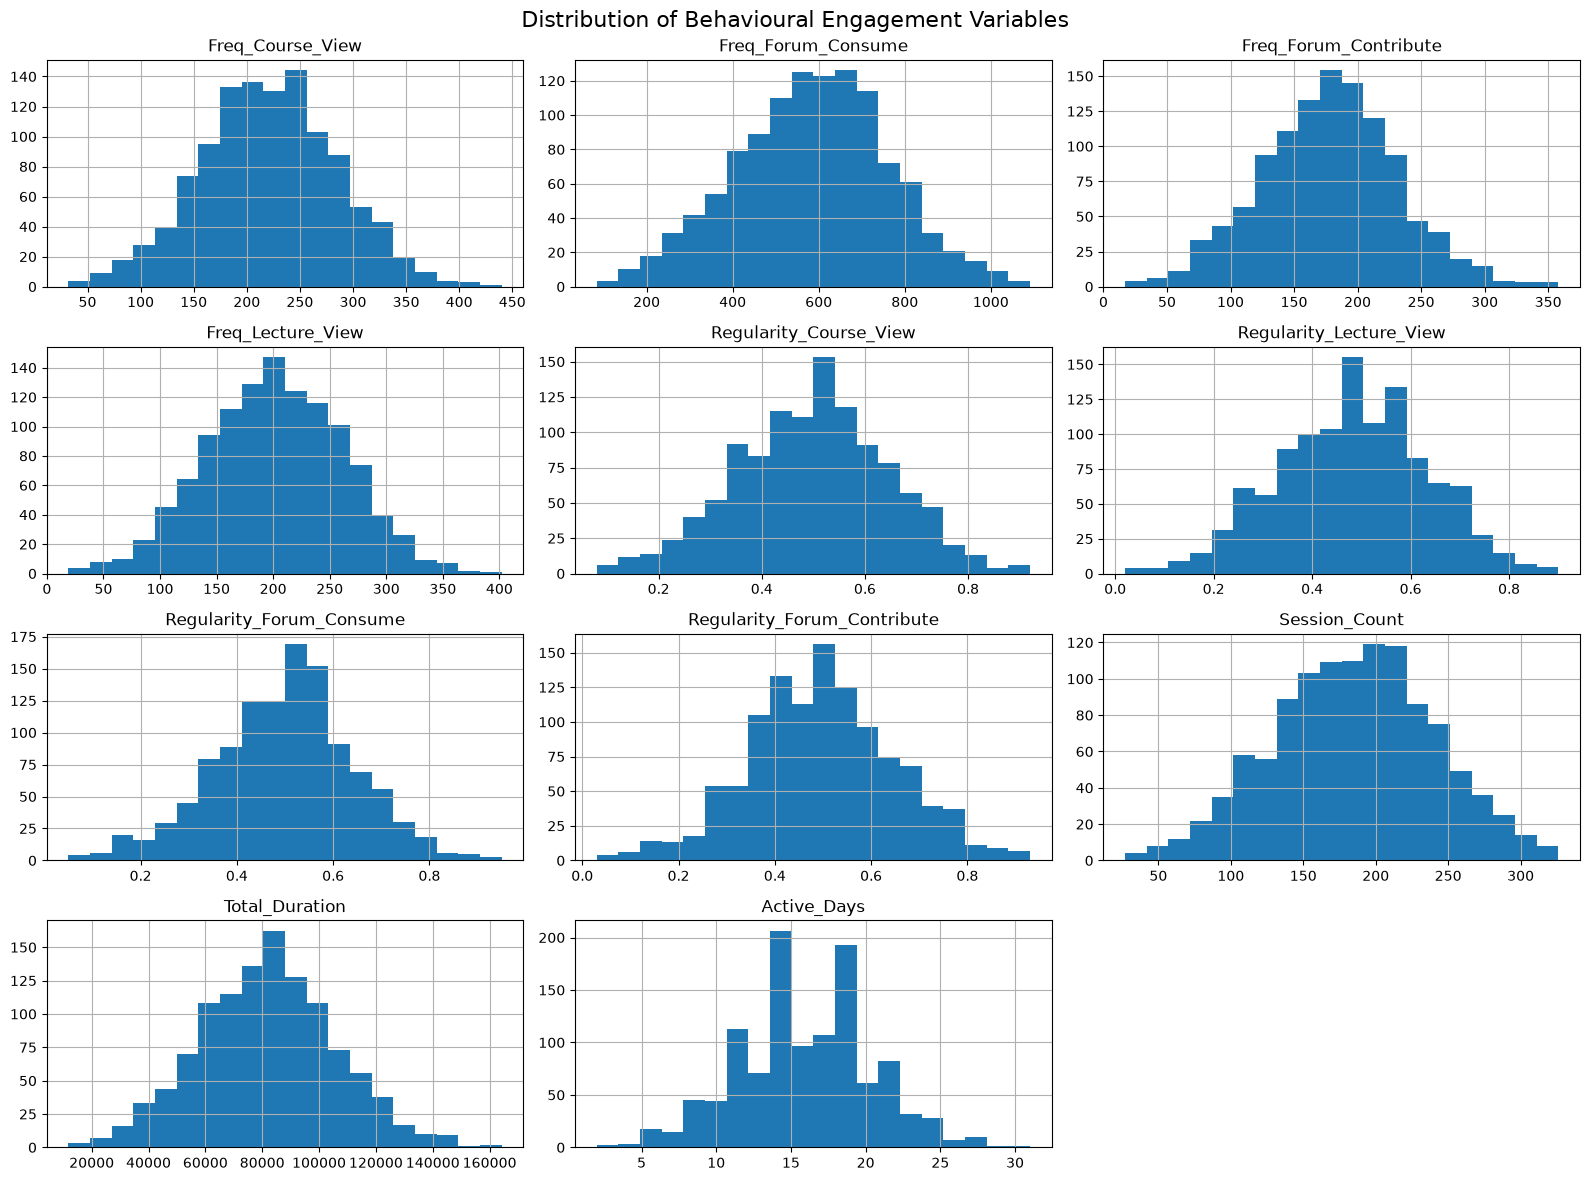

In [14]:
import matplotlib.pyplot as plt

behavior_columns = [
    "Freq_Course_View",
    "Freq_Forum_Consume",
    "Freq_Forum_Contribute",
    "Freq_Lecture_View",
    "Regularity_Course_View",
    "Regularity_Lecture_View",
    "Regularity_Forum_Consume",
    "Regularity_Forum_Contribute",
    "Session_Count",
    "Total_Duration",
    "Active_Days"
]

df[behavior_columns].hist(
    figsize=(16, 12),
    bins=20
)

plt.suptitle("Distribution of Behavioural Engagement Variables", fontsize=16)
plt.tight_layout()
plt.show()

In [15]:
sequence_behavior = df.groupby("Sequence")[
    [
        "Freq_Course_View",
        "Freq_Forum_Consume",
        "Freq_Forum_Contribute",
        "Freq_Lecture_View",
        "Session_Count",
        "Total_Duration",
        "Active_Days",
        "Final_Grade"
    ]
].mean()

sequence_behavior

,Freq_Course_View,Freq_Forum_Consume,Freq_Forum_Contribute,Freq_Lecture_View,Session_Count,Total_Duration,Active_Days,Final_Grade
Sequence,,,,,,,,
1,213.795775,572.464789,174.345070,196.204225,180.204225,80255.802817,15.690141,67.784085
2,219.387324,588.049296,178.197183,201.436620,185.760563,81532.943662,15.992958,68.542746
3,218.380282,571.492958,174.535211,201.239437,181.859155,80698.485915,15.753521,67.956620
4,225.690141,599.746479,183.119718,204.838028,188.246479,83660.605634,16.077465,68.598239
5,224.035211,587.021127,178.161972,204.577465,188.676056,82826.570423,16.316901,67.991408
6,220.471831,582.288732,177.471831,200.063380,182.816901,82154.901408,15.725352,67.824930
7,219.528169,588.112676,179.591549,200.218310,184.760563,82740.492958,15.929577,68.233732
8,221.309859,583.112676,176.570423,202.880282,186.154930,82191.873239,16.077465,68.451197


In [16]:
# Sort observations in chronological/sequence order
df_sorted = df.sort_values(["UserID", "Sequence"])

# Compare each user's first and last sequence
first_sequence = (
    df_sorted[df_sorted["Sequence"] == 1]
    .set_index("UserID")
)

last_sequence = (
    df_sorted[df_sorted["Sequence"] == 8]
    .set_index("UserID")
)

# Calculate change from Sequence 1 to Sequence 8
change = last_sequence[behavior_columns + ["Final_Grade"]] - first_sequence[behavior_columns + ["Final_Grade"]]

change.head(10)

,Freq_Course_View,Freq_Forum_Consume,Freq_Forum_Contribute,Freq_Lecture_View,Regularity_Course_View,Regularity_Lecture_View,Regularity_Forum_Consume,Regularity_Forum_Contribute,Session_Count,Total_Duration,Active_Days,Final_Grade
UserID,,,,,,,,,,,,
00050F0E,-55,323,100,-59,-0.03,-0.05,-0.03,-0.05,27,-4167,1,7.86
006DD50A,-45,-57,-17,-19,-0.07,-0.07,-0.07,-0.01,-57,-6772,-3,-8.41
05D0E111,26,-23,58,-25,0.28,0.23,0.06,0.24,37,-1514,5,1.03
0637AF03,-3,-71,-34,-21,0.19,0.13,0.09,0.00,31,-7635,8,4.71
065F7507,-34,-73,-33,-75,-0.02,-0.02,-0.10,0.00,-7,-14145,-1,-2.56
06AC3EDE,2,64,4,38,0.05,0.04,0.06,-0.11,-32,991,-3,0.51
08972814,121,1,-62,-14,0.05,-0.01,0.17,0.07,67,-8780,3,3.33
089734B8,-80,2,-55,-89,-0.32,-0.50,0.04,-0.11,-55,8913,-4,-3.32
0A30CA6E,-48,-150,-55,-26,0.11,-0.08,0.12,-0.23,-27,-16097,5,-5.37


In [17]:
from sklearn.preprocessing import StandardScaler

# Behavioural variables only
behavior_change = change[behavior_columns].copy()

# Standardize each behavioural change variable
scaler = StandardScaler()

standardized_change = pd.DataFrame(
    scaler.fit_transform(behavior_change),
    columns=behavior_change.columns,
    index=behavior_change.index
)

standardized_change.head(10)

,Freq_Course_View,Freq_Forum_Consume,Freq_Forum_Contribute,Freq_Lecture_View,Regularity_Course_View,Regularity_Lecture_View,Regularity_Forum_Consume,Regularity_Forum_Contribute,Session_Count,Total_Duration,Active_Days
UserID,,,,,,,,,,,
00050F0E,-0.893342,2.060146,2.134180,-0.916779,-0.249821,-0.350085,-0.240096,-0.214696,0.383263,-0.288556,0.119196
006DD50A,-0.750440,-0.446178,-0.419642,-0.358415,-0.470847,-0.469585,-0.459701,-0.018954,-1.146200,-0.411721,-0.659002
05D0E111,0.264169,-0.221928,1.217424,-0.442169,1.463129,1.322916,0.254015,1.204437,0.565342,-0.163121,0.897394
0637AF03,-0.150249,-0.538516,-0.790710,-0.386333,0.965820,0.725416,0.418718,0.029982,0.456095,-0.452524,1.481043
065F7507,-0.593247,-0.551707,-0.768883,-1.140125,-0.194565,-0.170835,-0.624405,0.029982,-0.235805,-0.760320,-0.269903
06AC3EDE,-0.078798,0.351889,0.038736,0.437254,0.192230,0.187666,0.254015,-0.508310,-0.691002,-0.044683,-0.659002
08972814,1.621743,-0.063633,-1.401882,-0.288619,0.192230,-0.111085,0.857928,0.372531,1.111579,-0.506660,0.508295
089734B8,-1.250599,-0.057038,-1.249089,-1.335552,-1.852258,-3.038836,0.144212,-0.508310,-1.109784,0.329872,-0.853552
0A30CA6E,-0.793311,-1.059567,-1.249089,-0.456128,0.523769,-0.529335,0.583422,-1.095538,-0.599963,-0.852611,0.897394


In [18]:
# Correlation between behavioural variables and final grade

correlation_columns = behavior_columns + ["Final_Grade"]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix.round(2)

,Freq_Course_View,Freq_Forum_Consume,Freq_Forum_Contribute,Freq_Lecture_View,Regularity_Course_View,Regularity_Lecture_View,Regularity_Forum_Consume,Regularity_Forum_Contribute,Session_Count,Total_Duration,Active_Days,Final_Grade
Freq_Course_View,1.00,0.65,0.42,0.65,0.72,0.70,0.51,0.24,0.87,0.71,0.79,0.41
Freq_Forum_Consume,0.65,1.00,0.81,0.36,0.53,0.46,0.51,0.35,0.74,0.87,0.61,0.52
Freq_Forum_Contribute,0.42,0.81,1.00,0.23,0.39,0.35,0.35,0.38,0.54,0.74,0.43,0.58
Freq_Lecture_View,0.65,0.36,0.23,1.00,0.51,0.57,0.30,0.11,0.58,0.52,0.56,0.22
Regularity_Course_View,0.72,0.53,0.39,0.51,1.00,0.72,0.59,0.25,0.82,0.54,0.88,0.40
Regularity_Lecture_View,0.70,0.46,0.35,0.57,0.72,1.00,0.40,0.20,0.74,0.54,0.72,0.37
Regularity_Forum_Consume,0.51,0.51,0.35,0.30,0.59,0.40,1.00,0.47,0.60,0.43,0.58,0.35
Regularity_Forum_Contribute,0.24,0.35,0.38,0.11,0.25,0.20,0.47,1.00,0.30,0.33,0.26,0.32
Session_Count,0.87,0.74,0.54,0.58,0.82,0.74,0.60,0.30,1.00,0.76,0.87,0.49
Total_Duration,0.71,0.87,0.74,0.52,0.54,0.54,0.43,0.33,0.76,1.00,0.62,0.51


In [19]:
# Calculate the preliminary Behavioural Change Index (BCI)

bci = standardized_change.mean(axis=1)

bci_df = pd.DataFrame({
    "BCI": bci
})

print("BCI summary:")
print(bci_df["BCI"].describe())

BCI summary:
count    1.420000e+02
mean     1.094586e-17
std      6.832607e-01
min     -2.012078e+00
25%     -4.293964e-01
50%     -4.200304e-03
75%      3.943749e-01
max      1.918596e+00
Name: BCI, dtype: float64


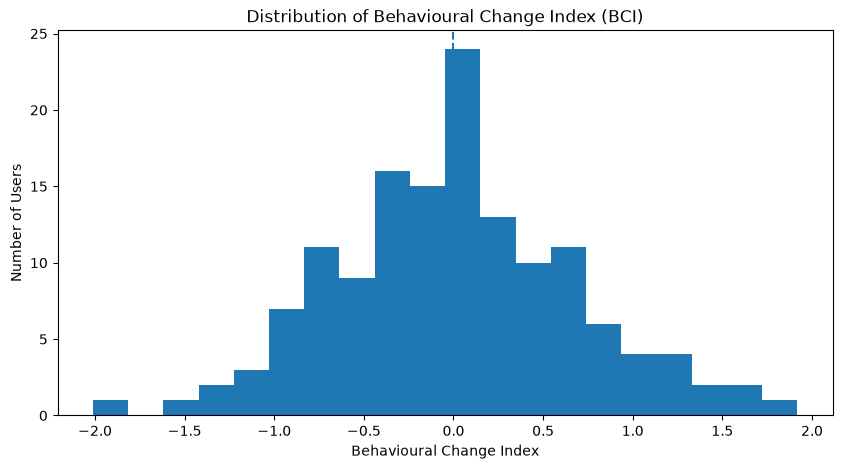

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(bci_df["BCI"], bins=20)

plt.axvline(0, linestyle="--")

plt.title("Distribution of Behavioural Change Index (BCI)")
plt.xlabel("Behavioural Change Index")
plt.ylabel("Number of Users")

plt.show()

In [21]:
# Define preliminary behavioural change categories

lower_threshold = bci_df["BCI"].quantile(0.25)
upper_threshold = bci_df["BCI"].quantile(0.75)

def classify_behavior(bci):
    if bci < lower_threshold:
        return "Declining"
    elif bci > upper_threshold:
        return "Improving"
    else:
        return "Stable"

bci_df["Behavior_State"] = bci_df["BCI"].apply(classify_behavior)

print("Thresholds:")
print("Declining threshold:", round(lower_threshold, 3))
print("Improving threshold:", round(upper_threshold, 3))

print("\nBehavior state counts:")
print(bci_df["Behavior_State"].value_counts())

print("\nBehavior state percentages:")
print(
    (bci_df["Behavior_State"].value_counts(normalize=True) * 100).round(2)
)

Thresholds:
Declining threshold: -0.429
Improving threshold: 0.394

Behavior state counts:
Behavior_State
Stable       70
Declining    36
Improving    36
Name: count, dtype: int64

Behavior state percentages:
Behavior_State
Stable       49.30
Declining    25.35
Improving    25.35
Name: proportion, dtype: float64


In [22]:
# Validate whether the BCI-based behaviour states
# show the expected direction of behavioural change

validation_df = standardized_change.copy()

validation_df["BCI"] = bci_df["BCI"]
validation_df["Behavior_State"] = bci_df["Behavior_State"]

# Add grade change only for supporting analysis
validation_df["Grade_Change"] = change["Final_Grade"]

validation_summary = (
    validation_df
    .groupby("Behavior_State")[behavior_columns + ["BCI", "Grade_Change"]]
    .mean()
    .round(2)
)

print("Behaviour State Validation:")
display(validation_summary)

Behaviour State Validation:


,Freq_Course_View,Freq_Forum_Consume,Freq_Forum_Contribute,Freq_Lecture_View,Regularity_Course_View,Regularity_Lecture_View,Regularity_Forum_Consume,Regularity_Forum_Contribute,Session_Count,Total_Duration,Active_Days,BCI,Grade_Change
Behavior_State,,,,,,,,,,,,,
Declining,-1.04,-0.94,-0.58,-0.71,-0.94,-0.90,-0.79,-0.26,-1.09,-0.98,-0.98,-0.84,-1.88
Improving,1.13,0.95,0.61,0.79,1.04,0.89,0.90,0.13,1.23,0.96,1.12,0.89,3.57
Stable,-0.04,-0.00,-0.02,-0.04,-0.05,0.01,-0.06,0.07,-0.07,0.01,-0.08,-0.02,0.49


In [23]:
# Create ML-ready user-level features using only Sequences 1–7
# Sequence 8 is kept out of the input features to avoid target leakage.

history_df = df[df["Sequence"] <= 7].copy()

# Behavioural columns
behavior_columns = [
    "Freq_Course_View",
    "Freq_Forum_Consume",
    "Freq_Forum_Contribute",
    "Freq_Lecture_View",
    "Regularity_Course_View",
    "Regularity_Lecture_View",
    "Regularity_Forum_Consume",
    "Regularity_Forum_Contribute",
    "Session_Count",
    "Total_Duration",
    "Active_Days"
]

# Sort chronologically
history_df = history_df.sort_values(["UserID", "Sequence"])

# Create user-level historical features
ml_features = history_df.groupby("UserID")[behavior_columns].agg(
    ["mean", "std"]
)

# Flatten column names
ml_features.columns = [
    f"{feature}_{stat}"
    for feature, stat in ml_features.columns
]

# Add most recent historical behaviour (Sequence 7)
seq7 = (
    history_df[history_df["Sequence"] == 7]
    .set_index("UserID")[behavior_columns]
)

seq7.columns = [f"{col}_recent" for col in seq7.columns]

ml_features = ml_features.join(seq7)

# Create target from our previously calculated BCI
ml_features["BCI"] = bci_df["BCI"]
ml_features["Behavior_State"] = bci_df["Behavior_State"]

print("ML-ready dataset created!")
print("Shape:", ml_features.shape)

display(ml_features.head())

ML-ready dataset created!
Shape: (142, 35)


,Freq_Course_View_mean,Freq_Course_View_std,Freq_Forum_Consume_mean,Freq_Forum_Consume_std,Freq_Forum_Contribute_mean,Freq_Forum_Contribute_std,Freq_Lecture_View_mean,Freq_Lecture_View_std,Regularity_Course_View_mean,Regularity_Course_View_std,...,Freq_Lecture_View_recent,Regularity_Course_View_recent,Regularity_Lecture_View_recent,Regularity_Forum_Consume_recent,Regularity_Forum_Contribute_recent,Session_Count_recent,Total_Duration_recent,Active_Days_recent,BCI,Behavior_State
UserID,,,,,,,,,,,,,,,,,,,,,
00050F0E,234.285714,34.740535,511.857143,157.806240,167.714286,57.346067,212.000000,24.460853,0.457143,0.097761,...,191,0.43,0.33,0.28,0.35,155,82944,12,0.140310,Stable
006DD50A,217.857143,63.758473,621.142857,56.111284,192.857143,25.241689,196.714286,5.529144,0.462857,0.063696,...,198,0.35,0.27,0.40,0.53,99,73773,8,-0.510062,Declining
05D0E111,190.428571,28.271642,501.714286,77.712535,125.000000,16.319722,228.000000,46.590414,0.508571,0.111270,...,269,0.60,0.45,0.60,0.44,178,68662,19,0.578328,Improving
0637AF03,314.428571,24.493925,894.285714,104.037997,210.142857,25.816200,229.285714,15.850492,0.588571,0.104471,...,236,0.56,0.45,0.58,0.56,266,122421,21,0.159886,Stable
065F7507,170.285714,33.821661,509.000000,108.845456,143.428571,31.915812,199.571429,35.584909,0.435714,0.069966,...,198,0.49,0.43,0.65,0.35,155,97111,13,-0.479983,Declining


In [24]:
# Separate input features (X) and target (y)

# BCI is excluded because it was used to create the target.
# Behavior_State is the target itself.
X = ml_features.drop(columns=["BCI", "Behavior_State"])

y = ml_features["Behavior_State"]

print("Feature matrix (X):", X.shape)
print("Target vector (y):", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

Feature matrix (X): (142, 33)
Target vector (y): (142,)

Target distribution:
Behavior_State
Stable       70
Declining    36
Improving    36
Name: count, dtype: int64

Feature columns:
['Freq_Course_View_mean', 'Freq_Course_View_std', 'Freq_Forum_Consume_mean', 'Freq_Forum_Consume_std', 'Freq_Forum_Contribute_mean', 'Freq_Forum_Contribute_std', 'Freq_Lecture_View_mean', 'Freq_Lecture_View_std', 'Regularity_Course_View_mean', 'Regularity_Course_View_std', 'Regularity_Lecture_View_mean', 'Regularity_Lecture_View_std', 'Regularity_Forum_Consume_mean', 'Regularity_Forum_Consume_std', 'Regularity_Forum_Contribute_mean', 'Regularity_Forum_Contribute_std', 'Session_Count_mean', 'Session_Count_std', 'Total_Duration_mean', 'Total_Duration_std', 'Active_Days_mean', 'Active_Days_std', 'Freq_Course_View_recent', 'Freq_Forum_Consume_recent', 'Freq_Forum_Contribute_recent', 'Freq_Lecture_View_recent', 'Regularity_Course_View_recent', 'Regularity_Lecture_View_recent', 'Regularity_Forum_Consume_recent

In [25]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set:
X_train: (113, 33)
y_train: (113,)

Testing set:
X_test: (29, 33)
y_test: (29,)

Training target distribution:
Behavior_State
Stable       56
Improving    29
Declining    28
Name: count, dtype: int64

Testing target distribution:
Behavior_State
Stable       14
Declining     8
Improving     7
Name: count, dtype: int64


In [26]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
# Predict behaviour states for unseen test users

y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("\nActual vs Predicted:")
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(comparison)

Predictions generated successfully!

Actual vs Predicted:


,Actual,Predicted
0,Stable,Stable
1,Stable,Declining
2,Improving,Stable
3,Stable,Stable
4,Declining,Stable
5,Stable,Improving
6,Stable,Improving
7,Improving,Stable
8,Declining,Declining
9,Improving,Improving


In [28]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")

# Detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Declining", "Stable", "Improving"]
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Declining", "Stable", "Improving"]
)

print("\nConfusion Matrix:")
print(cm)

Accuracy: 41.38%

Classification Report:
              precision    recall  f1-score   support

   Declining       0.29      0.25      0.27         8
      Stable       0.38      0.36      0.37        14
   Improving       0.56      0.71      0.62         7

    accuracy                           0.41        29
   macro avg       0.41      0.44      0.42        29
weighted avg       0.40      0.41      0.40        29


Confusion Matrix:
[[2 6 0]
 [5 5 4]
 [0 2 5]]


In [29]:
# Examine which features Random Forest considers important

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 features:")
display(feature_importance.head(15))

Top 15 features:


,Feature,Importance
0,Session_Count_std,0.052106
1,Regularity_Course_View_std,0.041276
2,Regularity_Forum_Consume_std,0.039023
3,Total_Duration_std,0.038148
4,Freq_Course_View_std,0.037994
5,Session_Count_recent,0.036663
6,Regularity_Course_View_mean,0.036356
7,Freq_Forum_Contribute_mean,0.035681
8,Regularity_Forum_Contribute_std,0.035529
9,Freq_Forum_Consume_mean,0.033368


In [30]:
# Create temporal trend (slope) features for Sequences 1–7

from scipy.stats import linregress

trend_features = {}

for feature in behavior_columns:
    trend_features[f"{feature}_trend"] = (
        history_df.groupby("UserID")
        .apply(
            lambda group: linregress(
                group["Sequence"],
                group[feature]
            ).slope,
            include_groups=False
        )
    )

trend_df = pd.DataFrame(trend_features)

# Add trend features to our existing ML features
ml_features_v2 = ml_features.drop(columns=["BCI", "Behavior_State"]).join(
    trend_df
)

# Add target back
ml_features_v2["Behavior_State"] = bci_df["Behavior_State"]

print("Updated ML dataset created!")
print("Shape:", ml_features_v2.shape)

print("\nNew trend features:")
print(trend_df.columns.tolist())

display(ml_features_v2.head())

Updated ML dataset created!
Shape: (142, 45)

New trend features:
['Freq_Course_View_trend', 'Freq_Forum_Consume_trend', 'Freq_Forum_Contribute_trend', 'Freq_Lecture_View_trend', 'Regularity_Course_View_trend', 'Regularity_Lecture_View_trend', 'Regularity_Forum_Consume_trend', 'Regularity_Forum_Contribute_trend', 'Session_Count_trend', 'Total_Duration_trend', 'Active_Days_trend']


,Freq_Course_View_mean,Freq_Course_View_std,Freq_Forum_Consume_mean,Freq_Forum_Consume_std,Freq_Forum_Contribute_mean,Freq_Forum_Contribute_std,Freq_Lecture_View_mean,Freq_Lecture_View_std,Regularity_Course_View_mean,Regularity_Course_View_std,...,Freq_Forum_Contribute_trend,Freq_Lecture_View_trend,Regularity_Course_View_trend,Regularity_Lecture_View_trend,Regularity_Forum_Consume_trend,Regularity_Forum_Contribute_trend,Session_Count_trend,Total_Duration_trend,Active_Days_trend,Behavior_State
UserID,,,,,,,,,,,,,,,,,,,,,
00050F0E,234.285714,34.740535,511.857143,157.806240,167.714286,57.346067,212.000000,24.460853,0.457143,0.097761,...,15.321429,-7.321429,0.008929,-0.013214,-0.021071,-1.035714e-02,3.357143,-2041.392857,0.321429,Stable
006DD50A,217.857143,63.758473,621.142857,56.111284,192.857143,25.241689,196.714286,5.529144,0.462857,0.063696,...,-0.321429,2.142857,-0.016071,-0.023929,-0.035000,-1.750000e-02,-13.750000,-2520.535714,-0.821429,Declining
05D0E111,190.428571,28.271642,501.714286,77.712535,125.000000,16.319722,228.000000,46.590414,0.508571,0.111270,...,6.535714,4.000000,0.025000,0.022857,0.015357,2.642857e-02,0.785714,-495.678571,0.464286,Improving
0637AF03,314.428571,24.493925,894.285714,104.037997,210.142857,25.816200,229.285714,15.850492,0.588571,0.104471,...,-7.857143,2.607143,0.010714,-0.004643,0.018571,3.965082e-18,3.857143,-3435.642857,0.392857,Stable
065F7507,170.285714,33.821661,509.000000,108.845456,143.428571,31.915812,199.571429,35.584909,0.435714,0.069966,...,4.321429,-6.392857,0.024643,0.025714,0.033214,1.428571e-03,11.035714,7538.142857,0.535714,Declining


In [31]:
# Prepare the updated feature matrix and target

X_v2 = ml_features_v2.drop(columns=["Behavior_State"])
y_v2 = ml_features_v2["Behavior_State"]

# Train-test split
X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y_v2,
    test_size=0.20,
    random_state=42,
    stratify=y_v2
)

print("Updated feature matrix:", X_v2.shape)
print("Target:", y_v2.shape)

print("\nTraining set:", X_train_v2.shape)
print("Testing set:", X_test_v2.shape)

print("\nTraining target distribution:")
print(y_train_v2.value_counts())

print("\nTesting target distribution:")
print(y_test_v2.value_counts())

Updated feature matrix: (142, 44)
Target: (142,)

Training set: (113, 44)
Testing set: (29, 44)

Training target distribution:
Behavior_State
Stable       56
Improving    29
Declining    28
Name: count, dtype: int64

Testing target distribution:
Behavior_State
Stable       14
Declining     8
Improving     7
Name: count, dtype: int64


In [32]:
# Train the improved Random Forest model

rf_model_v2 = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model_v2.fit(X_train_v2, y_train_v2)

print("Random Forest V2 trained successfully!")

Random Forest V2 trained successfully!


In [33]:
# Predict on the same unseen test users
y_pred_v2 = rf_model_v2.predict(X_test_v2)

# Calculate accuracy
accuracy_v2 = accuracy_score(y_test_v2, y_pred_v2)

print(f"Random Forest V2 Accuracy: {accuracy_v2:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_v2,
        y_pred_v2,
        labels=["Declining", "Stable", "Improving"]
    )
)

# Confusion matrix
cm_v2 = confusion_matrix(
    y_test_v2,
    y_pred_v2,
    labels=["Declining", "Stable", "Improving"]
)

print("\nConfusion Matrix:")
print(cm_v2)

print("\nAccuracy comparison:")
print(f"Original Random Forest: {accuracy:.2%}")
print(f"Random Forest V2:       {accuracy_v2:.2%}")

Random Forest V2 Accuracy: 68.97%

Classification Report:
              precision    recall  f1-score   support

   Declining       0.64      0.88      0.74         8
      Stable       0.78      0.50      0.61        14
   Improving       0.67      0.86      0.75         7

    accuracy                           0.69        29
   macro avg       0.69      0.74      0.70        29
weighted avg       0.71      0.69      0.68        29


Confusion Matrix:
[[7 1 0]
 [4 7 3]
 [0 1 6]]

Accuracy comparison:
Original Random Forest: 41.38%
Random Forest V2:       68.97%


In [34]:
# Feature importance for Random Forest V2

feature_importance_v2 = pd.DataFrame({
    "Feature": X_train_v2.columns,
    "Importance": rf_model_v2.feature_importances_
})

feature_importance_v2 = (
    feature_importance_v2
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 features used by Random Forest V2:")
display(feature_importance_v2.head(15))

Top 15 features used by Random Forest V2:


,Feature,Importance
0,Session_Count_trend,0.083834
1,Regularity_Course_View_trend,0.071210
2,Active_Days_trend,0.063182
3,Total_Duration_trend,0.052345
4,Regularity_Lecture_View_trend,0.048916
5,Freq_Course_View_trend,0.047946
6,Regularity_Forum_Consume_trend,0.035497
7,Freq_Forum_Consume_trend,0.034394
8,Session_Count_std,0.028379
9,Freq_Forum_Contribute_trend,0.027070


In [35]:
from sklearn.preprocessing import StandardScaler

# Use only behavioural features
# Exclude Behavior_State because it is our classification target.
X_anomaly = ml_features_v2.drop(columns=["Behavior_State"]).copy()

# Standardize features because they have very different scales
anomaly_scaler = StandardScaler()

X_anomaly_scaled = anomaly_scaler.fit_transform(X_anomaly)

print("Anomaly detection dataset prepared!")
print("Original shape:", X_anomaly.shape)
print("Scaled shape:", X_anomaly_scaled.shape)

Anomaly detection dataset prepared!
Original shape: (142, 44)
Scaled shape: (142, 44)


In [36]:
from sklearn.ensemble import IsolationForest

# Train Isolation Forest
isolation_model = IsolationForest(
    n_estimators=200,
    contamination=0.10,
    random_state=42
)

isolation_model.fit(X_anomaly_scaled)

print("Isolation Forest trained successfully!")

Isolation Forest trained successfully!


In [37]:
# Predict whether each user is normal or anomalous
anomaly_predictions = isolation_model.predict(X_anomaly_scaled)

# Add the predictions to a copy of our ML dataset
anomaly_results = ml_features_v2.copy()
anomaly_results["Anomaly_Flag"] = anomaly_predictions

print("Anomaly detection completed!")
print("\nAnomaly counts:")
print(anomaly_results["Anomaly_Flag"].value_counts())

Anomaly detection completed!

Anomaly counts:
Anomaly_Flag
 1    127
-1     15
Name: count, dtype: int64


In [38]:
# Display users identified as anomalies
anomalies = anomaly_results[
    anomaly_results["Anomaly_Flag"] == -1
].copy()

print("Number of anomalous users:", len(anomalies))

display(
    anomalies[
        ["Behavior_State", "Anomaly_Flag"]
    ].sort_index()
)

Number of anomalous users: 15


,Behavior_State,Anomaly_Flag
UserID,,
173E67ED,Stable,-1
2926CF64,Stable,-1
51A82B85,Stable,-1
5F9F6279,Declining,-1
72C883A2,Improving,-1
80EF3C8F,Improving,-1
985AFF35,Improving,-1
AF83680E,Stable,-1
B2BB60FE,Improving,-1


In [39]:
# Calculate anomaly scores
anomaly_scores = isolation_model.decision_function(X_anomaly_scaled)

# Add scores to our results
anomaly_results["Anomaly_Score"] = anomaly_scores

# Show the most unusual users first
most_anomalous = anomaly_results[
    anomaly_results["Anomaly_Flag"] == -1
].sort_values("Anomaly_Score")

print("Most anomalous users:")
display(
    most_anomalous[
        ["Behavior_State", "Anomaly_Flag", "Anomaly_Score"]
    ]
)

Most anomalous users:


,Behavior_State,Anomaly_Flag,Anomaly_Score
UserID,,,
EFC42628,Improving,-1,-0.162096
D2C5F64E,Improving,-1,-0.144763
80EF3C8F,Improving,-1,-0.128764
2926CF64,Stable,-1,-0.091567
D92F8056,Stable,-1,-0.075429
C83FF0BD,Stable,-1,-0.068047
173E67ED,Stable,-1,-0.060939
5F9F6279,Declining,-1,-0.048093
72C883A2,Improving,-1,-0.042435


In [40]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP imported successfully!")

SHAP version: 0.52.0
SHAP imported successfully!


In [41]:
# Create SHAP explainer for the Random Forest model
explainer = shap.TreeExplainer(rf_model_v2)

print("SHAP TreeExplainer created successfully!")

SHAP TreeExplainer created successfully!


In [42]:
# Calculate SHAP values for the test data
shap_values = explainer.shap_values(X_test_v2)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


In [43]:
print("Type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    for i, values in enumerate(shap_values):
        print(f"Class {i} shape:", values.shape)
else:
    print("SHAP values shape:", shap_values.shape)

print("Test data shape:", X_test_v2.shape)


Type: <class 'numpy.ndarray'>
SHAP values shape: (29, 44, 3)
Test data shape: (29, 44)


In [44]:
print("Random Forest class order:")
print(rf_model_v2.classes_)

Random Forest class order:
['Declining' 'Improving' 'Stable']


In [45]:
# Select the first user from the test set
user_index = 0

# Get the user's actual and predicted behaviour state
actual_state = y_test_v2.iloc[user_index]
predicted_state = rf_model_v2.predict(
    X_test_v2.iloc[[user_index]]
)[0]

# Find the SHAP class index corresponding to the predicted state
class_index = list(rf_model_v2.classes_).index(predicted_state)

# Get SHAP values for the predicted class
user_shap_values = shap_values[user_index, :, class_index]

# Create a table of features and their SHAP contributions
explanation = pd.DataFrame({
    "Feature": X_test_v2.columns,
    "Feature_Value": X_test_v2.iloc[user_index].values,
    "SHAP_Value": user_shap_values
})

# Sort by absolute SHAP value
explanation["Absolute_SHAP"] = explanation["SHAP_Value"].abs()

explanation = explanation.sort_values(
    "Absolute_SHAP",
    ascending=False
)

print("Actual Behaviour State:", actual_state)
print("Predicted Behaviour State:", predicted_state)
print("Class explained:", predicted_state)

display(
    explanation[
        ["Feature", "Feature_Value", "SHAP_Value"]
    ].head(10)
)

Actual Behaviour State: Stable
Predicted Behaviour State: Stable
Class explained: Stable


,Feature,Feature_Value,SHAP_Value
37,Regularity_Course_View_trend,0.012500,0.050435
43,Active_Days_trend,0.250000,0.035020
41,Session_Count_trend,-3.107143,-0.032826
38,Regularity_Lecture_View_trend,-0.014643,-0.031379
42,Total_Duration_trend,-1417.000000,0.030770
17,Session_Count_std,21.715695,0.029749
19,Total_Duration_std,11202.905046,0.019193
10,Regularity_Lecture_View_mean,0.622857,0.015876
33,Freq_Course_View_trend,-2.178571,-0.015627
20,Active_Days_mean,19.285714,0.015413


In [46]:
# Get the top 5 features influencing this prediction
top_5_explanation = explanation.head(5).copy()

# Add contribution direction
top_5_explanation["Direction"] = top_5_explanation["SHAP_Value"].apply(
    lambda x: "Toward prediction" if x > 0 else "Away from prediction"
)

print("Top 5 SHAP explanations:")
display(
    top_5_explanation[
        ["Feature", "Feature_Value", "SHAP_Value", "Direction"]
    ]
)

Top 5 SHAP explanations:


,Feature,Feature_Value,SHAP_Value,Direction
37,Regularity_Course_View_trend,0.012500,0.050435,Toward prediction
43,Active_Days_trend,0.250000,0.035020,Toward prediction
41,Session_Count_trend,-3.107143,-0.032826,Away from prediction
38,Regularity_Lecture_View_trend,-0.014643,-0.031379,Away from prediction
42,Total_Duration_trend,-1417.000000,0.030770,Toward prediction


In [47]:
# Create SHAP explanations for every test user

all_explanations = []

for i in range(len(X_test_v2)):

    # Get predicted class
    predicted_state = rf_model_v2.predict(
        X_test_v2.iloc[[i]]
    )[0]

    # Find the corresponding SHAP class index
    class_index = list(rf_model_v2.classes_).index(predicted_state)

    # SHAP values for the predicted class
    user_shap = shap_values[i, :, class_index]

    # Create explanation dataframe
    user_explanation = pd.DataFrame({
        "UserID": X_test_v2.index[i],
        "Predicted_State": predicted_state,
        "Feature": X_test_v2.columns,
        "Feature_Value": X_test_v2.iloc[i].values,
        "SHAP_Value": user_shap
    })

    # Keep strongest 5 contributors
    user_explanation["Absolute_SHAP"] = (
        user_explanation["SHAP_Value"].abs()
    )

    user_explanation = user_explanation.sort_values(
        "Absolute_SHAP",
        ascending=False
    ).head(5)

    all_explanations.append(user_explanation)

# Combine all users
shap_explanations_df = pd.concat(
    all_explanations,
    ignore_index=True
)

print("SHAP explanations generated!")
print("Number of users:", shap_explanations_df["UserID"].nunique())
print("Rows:", len(shap_explanations_df))

display(shap_explanations_df.head(10))

SHAP explanations generated!
Number of users: 29
Rows: 145


,UserID,Predicted_State,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
0,2BF8BAB5,Stable,Regularity_Course_View_trend,0.012500,0.050435,0.050435
1,2BF8BAB5,Stable,Active_Days_trend,0.250000,0.035020,0.035020
2,2BF8BAB5,Stable,Session_Count_trend,-3.107143,-0.032826,0.032826
3,2BF8BAB5,Stable,Regularity_Lecture_View_trend,-0.014643,-0.031379,0.031379
4,2BF8BAB5,Stable,Total_Duration_trend,-1417.000000,0.030770,0.030770
5,B235D544,Declining,Session_Count_trend,-6.785714,0.081604,0.081604
6,B235D544,Declining,Regularity_Course_View_trend,-0.032500,0.073846,0.073846
7,B235D544,Declining,Freq_Course_View_trend,5.035714,-0.069911,0.069911
8,B235D544,Declining,Active_Days_trend,-0.678571,0.059775,0.059775
9,B235D544,Declining,Regularity_Lecture_View_trend,-0.011429,0.043485,0.043485


In [48]:
import joblib
from pathlib import Path

# Make sure the models directory exists
Path("../models").mkdir(exist_ok=True)

# Save Random Forest classifier
joblib.dump(
    rf_model_v2,
    "../models/random_forest_v2.pkl"
)

# Save Isolation Forest model
joblib.dump(
    isolation_model,
    "../models/isolation_forest.pkl"
)

# Save anomaly scaler
joblib.dump(
    anomaly_scaler,
    "../models/anomaly_scaler.pkl"
)

print("ML models saved successfully!")
print("\nSaved files:")
print("- models/random_forest_v2.pkl")
print("- models/isolation_forest.pkl")
print("- models/anomaly_scaler.pkl")

ML models saved successfully!

Saved files:
- models/random_forest_v2.pkl
- models/isolation_forest.pkl
- models/anomaly_scaler.pkl


In [50]:
def generate_recommendation(behavior_state, anomaly_flag):
    """
    Generate a transparent recommendation based on
    behavioural state and anomaly status.
    """

    if behavior_state == "Improving" and anomaly_flag == -1:
        return "Behaviour is improving, but the pattern is unusual. Review recent activity for context."

    elif behavior_state == "Improving" and anomaly_flag == 1:
        return "Behaviour is improving. Continue the current positive pattern."

    elif behavior_state == "Stable" and anomaly_flag == -1:
        return "Behaviour is stable overall, but an unusual pattern was detected. Review recent activity."

    elif behavior_state == "Stable" and anomaly_flag == 1:
        return "Behaviour is stable. Maintain the current pattern and continue monitoring."

    elif behavior_state == "Declining" and anomaly_flag == -1:
        return "Behaviour is declining and an unusual pattern was detected. Consider timely review and support."

    elif behavior_state == "Declining" and anomaly_flag == 1:
        return "Behaviour is declining. Monitor recent activity and consider appropriate support."

    else:
        return "Continue monitoring behavioural trends."


print("Final recommendation function created successfully!")

Final recommendation function created successfully!


In [51]:
# Generate a recommendation for every user
anomaly_results["Recommendation"] = anomaly_results.apply(
    lambda row: generate_recommendation(
        row["Behavior_State"],
        row["Anomaly_Flag"]
    ),
    axis=1
)

print("Recommendations generated successfully!")
print("Total users:", len(anomaly_results))

display(
    anomaly_results[
        [
            "Behavior_State",
            "Anomaly_Flag",
            "Anomaly_Score",
            "Recommendation"
        ]
    ].head(10)
)

Recommendations generated successfully!
Total users: 142


,Behavior_State,Anomaly_Flag,Anomaly_Score,Recommendation
UserID,,,,
00050F0E,Stable,1,0.056862,Behaviour is stable. Maintain the current patt...
006DD50A,Declining,1,0.051673,Behaviour is declining. Monitor recent activit...
05D0E111,Improving,1,0.079842,Behaviour is improving. Continue the current p...
0637AF03,Stable,1,0.056227,Behaviour is stable. Maintain the current patt...
065F7507,Declining,1,0.068789,Behaviour is declining. Monitor recent activit...
06AC3EDE,Stable,1,0.100072,Behaviour is stable. Maintain the current patt...
08972814,Stable,1,0.105207,Behaviour is stable. Maintain the current patt...
089734B8,Declining,1,0.068322,Behaviour is declining. Monitor recent activit...
0A30CA6E,Stable,1,0.081022,Behaviour is stable. Maintain the current patt...


In [52]:
def generate_alert_priority(behavior_state, anomaly_flag):
    """
    Assign a monitoring priority based on
    behavioural state and anomaly status.
    """

    if behavior_state == "Declining" and anomaly_flag == -1:
        return "High"

    elif behavior_state == "Declining" and anomaly_flag == 1:
        return "Medium"

    elif behavior_state == "Stable" and anomaly_flag == -1:
        return "Medium"

    elif behavior_state == "Stable" and anomaly_flag == 1:
        return "Low"

    elif behavior_state == "Improving" and anomaly_flag == -1:
        return "Medium"

    elif behavior_state == "Improving" and anomaly_flag == 1:
        return "Low"

    else:
        return "Low"


print("Alert priority function created successfully!")

Alert priority function created successfully!


In [53]:
anomaly_results["Alert_Priority"] = anomaly_results.apply(
    lambda row: generate_alert_priority(
        row["Behavior_State"],
        row["Anomaly_Flag"]
    ),
    axis=1
)

print("Alert priorities generated successfully!")
print("Total users:", len(anomaly_results))

display(
    anomaly_results[
        [
            "Behavior_State",
            "Anomaly_Flag",
            "Anomaly_Score",
            "Alert_Priority",
            "Recommendation"
        ]
    ].head(10)
)

Alert priorities generated successfully!
Total users: 142


,Behavior_State,Anomaly_Flag,Anomaly_Score,Alert_Priority,Recommendation
UserID,,,,,
00050F0E,Stable,1,0.056862,Low,Behaviour is stable. Maintain the current patt...
006DD50A,Declining,1,0.051673,Medium,Behaviour is declining. Monitor recent activit...
05D0E111,Improving,1,0.079842,Low,Behaviour is improving. Continue the current p...
0637AF03,Stable,1,0.056227,Low,Behaviour is stable. Maintain the current patt...
065F7507,Declining,1,0.068789,Medium,Behaviour is declining. Monitor recent activit...
06AC3EDE,Stable,1,0.100072,Low,Behaviour is stable. Maintain the current patt...
08972814,Stable,1,0.105207,Low,Behaviour is stable. Maintain the current patt...
089734B8,Declining,1,0.068322,Medium,Behaviour is declining. Monitor recent activit...
0A30CA6E,Stable,1,0.081022,Low,Behaviour is stable. Maintain the current patt...


In [54]:
print("Alert Priority Distribution:")
print(
    anomaly_results["Alert_Priority"]
    .value_counts()
)

print("\nBehaviour State + Anomaly + Priority:")
print(
    anomaly_results[
        ["Behavior_State", "Anomaly_Flag", "Alert_Priority"]
    ]
    .value_counts()
    .sort_index()
)

Alert Priority Distribution:
Alert_Priority
Low       93
Medium    47
High       2
Name: count, dtype: int64

Behaviour State + Anomaly + Priority:
Behavior_State  Anomaly_Flag  Alert_Priority
Declining       -1            High               2
                 1            Medium            34
Improving       -1            Medium             7
                 1            Low               29
Stable          -1            Medium             6
                 1            Low               64
Name: count, dtype: int64


In [55]:
from pathlib import Path

# Create processed-data directory if it doesn't exist
Path("../data/processed").mkdir(exist_ok=True)

# Create final decision dataset
decision_results = anomaly_results[
    [
        "Behavior_State",
        "Anomaly_Flag",
        "Anomaly_Score",
        "Recommendation",
        "Alert_Priority"
    ]
].copy()

# Move UserID from index into a normal column
decision_results = decision_results.reset_index()

# Rename UserID column explicitly
decision_results = decision_results.rename(
    columns={"index": "UserID"}
)

# Add BCI
decision_results["BCI"] = bci_df["BCI"].values

# Reorder columns
decision_results = decision_results[
    [
        "UserID",
        "BCI",
        "Behavior_State",
        "Anomaly_Flag",
        "Anomaly_Score",
        "Alert_Priority",
        "Recommendation"
    ]
]

# Save
output_path = "../data/processed/decision_results.csv"

decision_results.to_csv(
    output_path,
    index=False
)

print("Decision results saved successfully!")
print("Shape:", decision_results.shape)
print("Saved to:", output_path)

display(decision_results.head(10))

Decision results saved successfully!
Shape: (142, 7)
Saved to: ../data/processed/decision_results.csv


,UserID,BCI,Behavior_State,Anomaly_Flag,Anomaly_Score,Alert_Priority,Recommendation
0,00050F0E,0.140310,Stable,1,0.056862,Low,Behaviour is stable. Maintain the current patt...
1,006DD50A,-0.510062,Declining,1,0.051673,Medium,Behaviour is declining. Monitor recent activit...
2,05D0E111,0.578328,Improving,1,0.079842,Low,Behaviour is improving. Continue the current p...
3,0637AF03,0.159886,Stable,1,0.056227,Low,Behaviour is stable. Maintain the current patt...
4,065F7507,-0.479983,Declining,1,0.068789,Medium,Behaviour is declining. Monitor recent activit...
5,06AC3EDE,-0.047273,Stable,1,0.100072,Low,Behaviour is stable. Maintain the current patt...
6,08972814,0.208402,Stable,1,0.105207,Low,Behaviour is stable. Maintain the current patt...
7,089734B8,-0.980085,Declining,1,0.068322,Medium,Behaviour is declining. Monitor recent activit...
8,0A30CA6E,-0.420996,Stable,1,0.081022,Low,Behaviour is stable. Maintain the current patt...
9,13FE5766,0.045771,Stable,1,0.092867,Low,Behaviour is stable. Maintain the current patt...


In [56]:
import json
from pathlib import Path

# Save the exact feature order used by the Random Forest
feature_columns = list(X_v2.columns)

feature_path = Path("../models/feature_columns.json")

with open(feature_path, "w") as f:
    json.dump(feature_columns, f, indent=4)

print("Feature column order saved successfully!")
print("Number of features:", len(feature_columns))
print("Saved to:", feature_path)

print("\nFirst 10 features:")
for feature in feature_columns[:10]:
    print("-", feature)

Feature column order saved successfully!
Number of features: 44
Saved to: ..\models\feature_columns.json

First 10 features:
- Freq_Course_View_mean
- Freq_Course_View_std
- Freq_Forum_Consume_mean
- Freq_Forum_Consume_std
- Freq_Forum_Contribute_mean
- Freq_Forum_Contribute_std
- Freq_Lecture_View_mean
- Freq_Lecture_View_std
- Regularity_Course_View_mean
- Regularity_Course_View_std


In [58]:
from pathlib import Path

docs_path = Path("../docs")
docs_path.mkdir(exist_ok=True)

ml_documentation = """
# PRJ_221 – Machine Learning Methodology

## 1. Dataset

The project uses the `LongitudinalEngagement.csv` dataset.

The dataset contains 1,136 records from 142 users, with 8 sequential
observations per user. The `Sequence` variable represents the order of
the course sequence and is not a calendar-based week or month.

The dataset contains engagement and activity variables such as:

- Course views
- Forum consumption
- Forum contribution
- Lecture views
- Activity regularity
- Session count
- Total duration
- Active days
- Final grade

The dataset does not directly contain attendance, task-completion, or
productivity variables.

The dataset is treated as simulated longitudinal learning data, and
results are not interpreted as population-level conclusions about real
students.

## 2. Behavioural Change Index

The dataset does not contain a direct target representing:

- Improving
- Stable
- Declining

Therefore, a Behavioural Change Index (BCI) was constructed.

For each user, behavioural changes between Sequence 1 and Sequence 8
were calculated for the 11 behavioural variables.

Because the variables have different scales, their changes were
standardized using StandardScaler.

The BCI was calculated as the mean of the standardized behavioural
changes across the 11 variables.

A positive BCI indicates an overall positive direction of change across
the selected behavioural variables, while a negative BCI indicates an
overall negative direction.

## 3. Behavioural State

Users were divided into three relative behavioural states using the
25th and 75th percentiles of the BCI distribution:

- Declining: BCI below the 25th percentile
- Stable: BCI between the 25th and 75th percentiles
- Improving: BCI above the 75th percentile

Thresholds obtained from the dataset:

- Declining: BCI < -0.429
- Stable: -0.429 <= BCI <= 0.394
- Improving: BCI > 0.394

The resulting distribution was:

- Stable: 70 users
- Declining: 36 users
- Improving: 36 users

These are relative data-driven categories and should not be interpreted
as absolute measures of a person's overall wellbeing or performance.

## 4. Feature Engineering

The first seven sequences were used as historical input information.

For each behavioural variable, the following features were created:

1. Mean across Sequences 1–7
2. Standard deviation across Sequences 1–7
3. Recent value from Sequence 7
4. Linear trend across Sequences 1–7

This produced 44 input features.

Trend features were calculated using the slope of a linear regression
between Sequence number and the corresponding behavioural variable.

## 5. Random Forest Classification

A Random Forest classifier was trained to predict the behavioural state.

Configuration:

- Number of trees: 200
- Random state: 42
- Class weighting: balanced
- Test size: 20%
- Stratified train/test split
- Training users: 113
- Test users: 29

The model using historical statistics and trend features achieved:

- Accuracy: 68.97%
- Macro F1-score: 0.70

The test set contained only 29 users, so these results should be
interpreted cautiously.

The model is intended to identify behavioural patterns in the available
dataset and does not establish causal relationships.

## 6. Isolation Forest Anomaly Detection

Isolation Forest was used to identify users whose behavioural feature
patterns were unusual relative to the dataset.

Configuration:

- Number of trees: 200
- Contamination assumption: 0.10
- Random state: 42

The model identified:

- 127 normal users
- 15 anomalous users

An anomaly means that the behavioural feature pattern is unusual
relative to the reference dataset. It does not automatically mean that
the behaviour is negative.

## 7. Explainable AI – SHAP

SHAP TreeExplainer was used to explain Random Forest predictions.

For each prediction, SHAP values indicate how individual features
contributed toward or away from the predicted class.

SHAP explanations are interpreted as model explanations, not causal
explanations.

The Random Forest class order is:

- Declining
- Improving
- Stable

## 8. Recommendation Layer

Recommendations are generated using transparent rule-based logic based
on:

- Behavioural state
- Anomaly status

The recommendation layer does not use an LLM to make decisions.

Examples:

- Improving + normal → continue the current positive pattern
- Stable + normal → maintain the current pattern
- Stable + anomaly → review recent activity
- Declining + normal → monitor recent activity and consider support
- Declining + anomaly → timely review and support

## 9. Alert Priority

Alert priority is generated using explicit rules:

| Behaviour State | Anomaly | Priority |
|---|---|---|
| Declining | Yes | High |
| Declining | No | Medium |
| Stable | Yes | Medium |
| Stable | No | Low |
| Improving | Yes | Medium |
| Improving | No | Low |

Priority represents the software's monitoring priority and is not a
diagnosis or judgement about a person.

## 10. Saved ML Artifacts

The following files are saved in the `models/` directory:

- `random_forest_v2.pkl`
- `isolation_forest.pkl`
- `anomaly_scaler.pkl`
- `feature_columns.json`

`feature_columns.json` preserves the exact 44-feature order expected by
the Random Forest model.

## 11. Important Limitations

1. The dataset contains only 142 users.
2. The target is engineered rather than directly labelled.
3. Behavioural state is defined relative to the BCI distribution.
4. The target uses Sequence 1-to-8 change, while prediction features
   use historical information through Sequence 7.
5. The current evaluation uses a single train/test split and therefore
   should not be treated as a definitive estimate of generalization.
6. The dataset represents simulated learning data and should not be
   generalized directly to real-world populations.
7. Model feature importance and SHAP values describe model behaviour;
   they do not establish causation.
8. Anomaly detection identifies unusual patterns, not necessarily
   undesirable behaviour.
"""

ml_file = docs_path / "ml_methodology.md"
ml_file.write_text(ml_documentation, encoding="utf-8")

print("ML methodology documentation saved successfully!")
print("Saved to:", ml_file)

ML methodology documentation saved successfully!
Saved to: ..\docs\ml_methodology.md
